(1) Concept of Linear Regression

Linear Regression is a statistical technique used to model the relationship between a dependent variable (target, Y) and one or more independent variables (predictors, X).

The goal is to fit a straight line (or hyperplane in higher dimensions) that best explains the relationship.




(2)Difference Between Simple and Multiple Linear Regression

Simple Linear Regression uses only one independent variable to predict the dependent variable, while Multiple Linear Regression uses two or more independent variables.

In SLR, the model fits a straight line to show the relationship, whereas in MLR, the model fits a plane (or hyperplane in higher dimensions).

SLR is easier to interpret but limited in scope, while MLR captures more complex relationships but may face issues like multicollinearity.



(3)Assumptions of Linear Regression

For linear regression to give valid results, these assumptions should hold:

Linearity:
Relationship between predictors (X) and target (Y) is linear.
If the relationship is curved, linear regression is not appropriate.

Independence of Errors:
Residuals (errors) should not be correlated with each other.

Homoscedasticity:
Variance of residuals should remain constant across all levels of predictors.
If variance changes (heteroscedasticity), predictions become unreliable.

Normality of Errors:
Residuals should be approximately normally distributed.
Helps in hypothesis testing and confidence intervals.

No Multicollinearity (for MLR):
Independent variables should not be highly correlated with each other.
High correlation between predictors makes coefficients unstable.

Import Libraries

In [ ]:
# If needed (run once). Comment out if already installed.
# !pip install pandas numpy scikit-learn matplotlib statsmodels

import warnings, re
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor


Load the dataset

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Student Mental Health Analysis During Online Learning.csv to Student Mental Health Analysis During Online Learning.csv


In [ ]:
import pandas as pd

# Use the exact name Colab saved it as
FILE_PATH = "Student Mental Health Analysis During Online Learning.csv"

# Load the dataset
df = pd.read_csv(FILE_PATH)

# Check shape and first rows
print(df.shape)
df.head(3)

(1000, 10)


,Name,Gender,Age,Education Level,Screen Time (hrs/day),Sleep Duration (hrs),Physical Activity (hrs/week),Stress Level,Anxious Before Exams,Academic Performance Change
0,Aarav,Male,15,Class 8,7.1,8.9,9.3,Medium,No,Same
1,Meera,Female,25,MSc,3.3,5.0,0.2,Medium,No,Same
2,Ishaan,Male,20,BTech,9.5,5.4,6.2,Medium,No,Same


Feature Selection & Preprocessing

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Define features (drop Name and target column)
X = df.drop(columns=["Name", "Stress Level"])
y = df["Stress Level"]

# 2. Identify categorical and numerical columns
categorical_cols = ["Gender", "Education Level", # "Stress Level", # Stress Level is now the target
                    "Anxious Before Exams", "Academic Performance Change"]
numeric_cols = ["Age", "Screen Time (hrs/day)",
                "Sleep Duration (hrs)", "Physical Activity (hrs/week)"]

# 3. Preprocessing: OneHotEncode categorical + Standardize numeric
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first"), categorical_cols)
    ]
)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (800, 8)
y_train shape: (800,)


Model Training

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OrdinalEncoder
import numpy as np

# Ordinal encode the target variable
stress_levels = ['Low', 'Medium', 'High']
encoder = OrdinalEncoder(categories=[stress_levels])
y_train_encoded = encoder.fit_transform(y_train.values.reshape(-1, 1))
y_test_encoded = encoder.transform(y_test.values.reshape(-1, 1))


# Create pipeline: preprocessing + model
# The preprocessor already handles X
model = Pipeline(steps=[("preprocessor", preprocessor),
                        ("regressor", LinearRegression())])

# Train model
model.fit(X_train, y_train_encoded)

# Predict
y_pred_encoded = model.predict(X_test)

# Evaluate using the encoded values
print("MSE:", mean_squared_error(y_test_encoded, y_pred_encoded))
print("R² Score:", r2_score(y_test_encoded, y_pred_encoded))

MSE: 0.5024140013644588
R² Score: -0.04430264261995154


Try Advanced Models (Optional for higher impact)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OrdinalEncoder

# Ordinal encode the target variable
stress_levels = ['Low', 'Medium', 'High']
encoder = OrdinalEncoder(categories=[stress_levels])
y_train_encoded = encoder.fit_transform(y_train.values.reshape(-1, 1))
y_test_encoded = encoder.transform(y_test.values.reshape(-1, 1))


rf_model = Pipeline(steps=[("preprocessor", preprocessor),
                           ("regressor", RandomForestRegressor(n_estimators=100, random_state=42))])

# Train model using encoded target
rf_model.fit(X_train, y_train_encoded.ravel()) # Use ravel() to flatten the encoded y

# Predict using encoded target
rf_pred_encoded = rf_model.predict(X_test)


# Evaluate using the encoded values
print("Random Forest R²:", r2_score(y_test_encoded, rf_pred_encoded))

Random Forest R²: -0.0734628975265017


Data Visualization (Exploratory Insights)

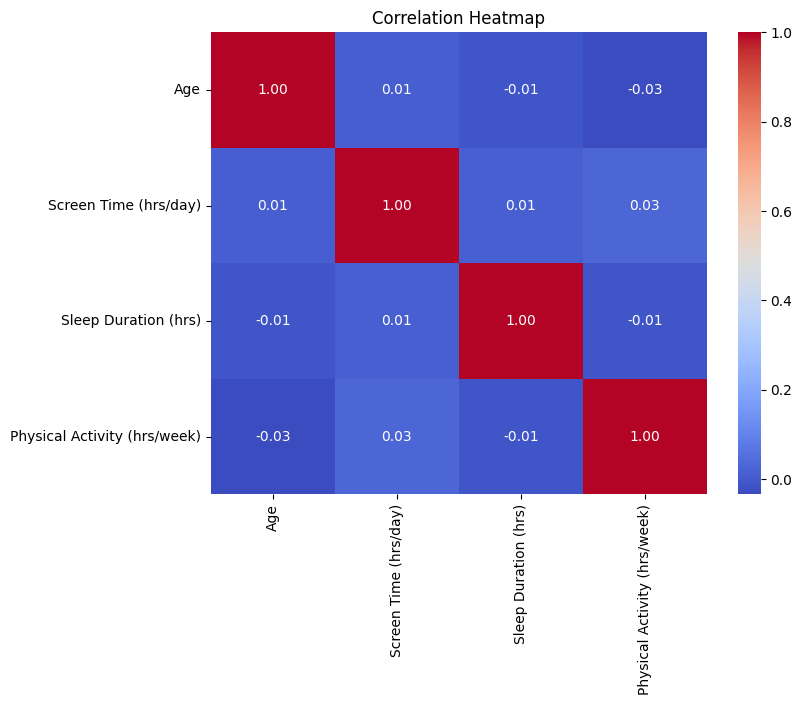

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation heatmap (only numeric)
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Distribution of target variable
# plt.figure(figsize=(6,4))
# sns.histplot(df["mh_index"], bins=10, kde=True)
# plt.title("Distribution of Mental Health Index")
# plt.show()

# Compare Stress Level vs mh_index
# plt.figure(figsize=(6,4))
# sns.boxplot(x="Stress Level", y="mh_index", data=df)
# plt.title("Stress Level vs Mental Health Index")
# plt.show()


Model Performance Visualization

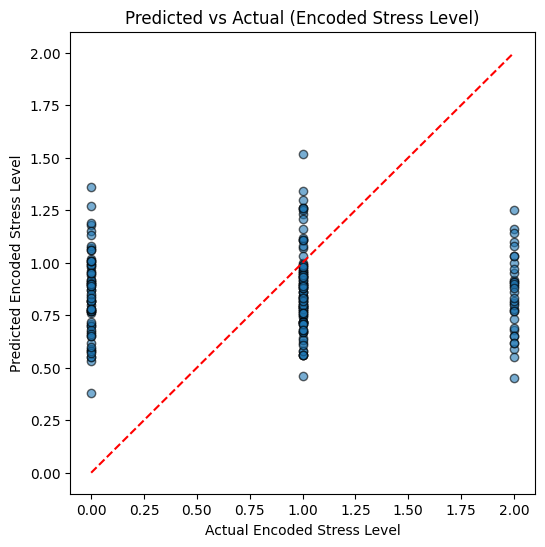

In [ ]:
# Predicted vs Actual for Random Forest (better model)
plt.figure(figsize=(6,6))
plt.scatter(y_test_encoded, rf_pred_encoded, alpha=0.6, edgecolors="k")
plt.xlabel("Actual Encoded Stress Level")
plt.ylabel("Predicted Encoded Stress Level")
plt.title("Predicted vs Actual (Encoded Stress Level)")
plt.plot([y_test_encoded.min(), y_test_encoded.max()], [y_test_encoded.min(), y_test_encoded.max()], "r--")  # diagonal line
plt.show()

Feature Importance (What impacts mental health most?)

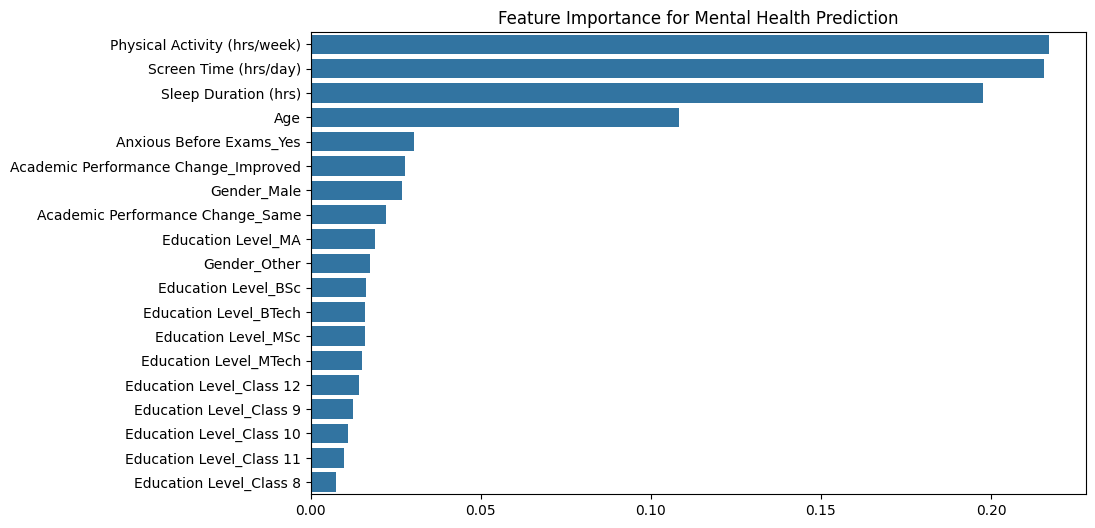

In [ ]:
# Extract feature names after preprocessing
ohe_features = rf_model.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_cols)
all_features = numeric_cols + list(ohe_features)

# Feature importance from Random Forest
importances = rf_model.named_steps["regressor"].feature_importances_
feat_imp = sorted(zip(all_features, importances), key=lambda x: x[1], reverse=True)

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=[x[1] for x in feat_imp], y=[x[0] for x in feat_imp])
plt.title("Feature Importance for Mental Health Prediction")
plt.show()


Project Report

Introduction: Mental health is a growing concern among students. Dataset includes stress, sleep, screen time, activity, etc.

Objective: Predict Mental Health Index (mh_index) using lifestyle factors.

EDA: Correlation, visualizations (show screen time ↑ stress ↑, sleep ↓, etc.).

Models Used: Linear Regression, Random Forest.

Results: R² score comparison, feature importance.

Conclusion: Stress level, sleep duration, and activity strongly affect mental health.

Future Work: Add real-time monitoring, mobile app integration, or deep learning.

